In [1]:
import pandas as pd

# download earthquakes (magnitude 4 and above) for India and nearby region
# we download one year at a time because the USGS site limits rows per request
all_years = []

for year in range(2000, 2027):
    url = (
        "https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
        f"&starttime={year}-01-01&endtime={year}-12-31T23:59:59"
        "&minlatitude=6&maxlatitude=37&minlongitude=68&maxlongitude=98"
        "&minmagnitude=4&orderby=time-asc"
    )
    try:
        part = pd.read_csv(url)
        print(year, "->", len(part), "earthquakes")
        all_years.append(part)
    except Exception as e:
        print(year, "-> no data or error:", e)

df = pd.concat(all_years, ignore_index=True)

# save a raw copy (we will upload this to GitHub too)
df.to_csv("india_earthquakes_raw.csv", index=False)

print("\nShape:", df.shape)
print(df.head())
print()
df.info()

2000 -> 290 earthquakes
2001 -> 442 earthquakes
2002 -> 444 earthquakes
2003 -> 312 earthquakes
2004 -> 871 earthquakes
2005 -> 2294 earthquakes
2006 -> 634 earthquakes
2007 -> 536 earthquakes
2008 -> 869 earthquakes
2009 -> 351 earthquakes
2010 -> 393 earthquakes
2011 -> 311 earthquakes
2012 -> 425 earthquakes
2013 -> 437 earthquakes
2014 -> 598 earthquakes
2015 -> 816 earthquakes
2016 -> 444 earthquakes
2017 -> 378 earthquakes
2018 -> 437 earthquakes
2019 -> 521 earthquakes
2020 -> 503 earthquakes
2021 -> 483 earthquakes
2022 -> 539 earthquakes
2023 -> 524 earthquakes
2024 -> 459 earthquakes
2025 -> 694 earthquakes
2026 -> 378 earthquakes

Shape: (15383, 22)
                       time  latitude  longitude  depth  mag magType  nst  \
0  2000-01-01T05:24:35.290Z    36.874     69.947   54.3  5.1     mwc  NaN   
1  2000-01-02T10:21:17.550Z    36.229     70.893   33.0  4.1      mb  NaN   
2  2000-01-02T10:23:58.980Z    27.559     92.498   33.0  5.0      mb  NaN   
3  2000-01-03T22:34:12.

**Markdown cell**

# Task 3: Earthquake Activity in India and Nearby Regions (2000-2026)

**Dataset:** USGS Earthquake Catalog (real seismograph records, official US Geological Survey source)
**Region:** latitude 6 to 37, longitude 68 to 98 (India, Himalayas and neighbouring countries)
**Filter:** magnitude 4 and above, January 2000 to October 2026

**Goal:** understand where earthquakes happen, how strong and how deep they are, how activity changes over time, and what this means for earthquake risk in India.

**Explore the data**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# load the raw file saved earlier (if the file is missing, re-run the download cell)
raw = pd.read_csv("india_earthquakes_raw.csv")
df = raw.copy()

print("Rows, columns:", df.shape)
print()
print(df.dtypes)

# missing values: count and percent
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
print("\nMissing values:")
print(pd.DataFrame({"missing": missing, "percent": missing_pct}).sort_values("percent", ascending=False).head(10))

# duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate event ids:", df["id"].duplicated().sum())

# categories
print("\nEvent types:")
print(df["type"].value_counts())
print("\nMagnitude types:")
print(df["magType"].value_counts())
print("\nReview status:")
print(df["status"].value_counts())

# numbers
print()
print(df[["depth", "mag"]].describe())
print("Negative depths:", (df["depth"] < 0).sum())

Rows, columns: (15383, 22)

time                object
latitude           float64
longitude          float64
depth              float64
mag                float64
magType             object
nst                float64
gap                float64
dmin               float64
rms                float64
net                 object
id                  object
updated             object
place               object
type                object
horizontalError    float64
depthError         float64
magError           float64
magNst             float64
status              object
locationSource      object
magSource           object
dtype: object

Missing values:
                 missing  percent
horizontalError     8955     58.2
magError            8436     54.8
dmin                8398     54.6
depthError          5477     35.6
nst                 4653     30.2
gap                 1239      8.1
magNst              1224      8.0
rms                    8      0.1
magType                0      0.0
mag    

**Clean the data**

In [3]:
# 1. remove duplicate events
before = len(df)
df = df.drop_duplicates(subset="id")
print("Duplicates removed:", before - len(df))

# 2. keep only real earthquakes (remove blasts, etc.)
before = len(df)
df = df[df["type"] == "earthquake"]
print("Non-earthquake events removed:", before - len(df))
df = df.drop(columns=["type"])

# 3. fix data types
df["time"] = pd.to_datetime(df["time"], utc=True)

# 4. fix inconsistent text
df["magType"] = df["magType"].str.lower().str.strip()
df["place"] = df["place"].str.strip()
for col in ["magType", "net", "status"]:
    df[col] = df[col].astype("category")

# 5. drop columns that are more than 50% empty, and columns we do not need
missing_pct = df.isnull().mean() * 100
drop_cols = missing_pct[missing_pct > 50].index.tolist()
print("Dropping (over 50% missing):", drop_cols)
df = df.drop(columns=drop_cols)
df = df.drop(columns=["updated", "locationSource", "magSource"])

# 6. check the important columns have no gaps
print("\nMissing in key columns:")
print(df[["time", "latitude", "longitude", "depth", "mag"]].isnull().sum())

# 7. outliers using the IQR rule
def check_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((series < low) | (series > high)).sum()
    return count, round(low, 2), round(high, 2)

for col in ["depth", "mag"]:
    count, low, high = check_outliers(df[col])
    print(col, "-> outliers:", count, "| normal range:", low, "to", high)

print("\nThese outliers are real measurements (very deep or very strong quakes), so we keep them.")
print("Rows left:", len(df))

Duplicates removed: 0
Non-earthquake events removed: 2
Dropping (over 50% missing): ['dmin', 'horizontalError', 'magError']

Missing in key columns:
time         0
latitude     0
longitude    0
depth        0
mag          0
dtype: int64
depth -> outliers: 1258 | normal range: -100.97 to 194.95
mag -> outliers: 402 | normal range: 3.45 to 5.45

These outliers are real measurements (very deep or very strong quakes), so we keep them.
Rows left: 15381


**New columns**

In [4]:
# time columns
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month

# country = the text after the last comma in "place"
df["country"] = df["place"].str.split(",").str[-1].str.strip()

# magnitude class
df["mag_class"] = pd.cut(
    df["mag"],
    bins=[3.9, 4.9, 5.9, 6.9, 10],
    labels=["Light (4-4.9)", "Moderate (5-5.9)", "Strong (6-6.9)", "Major (7+)"]
)

# depth class
df["depth_class"] = pd.cut(
    df["depth"],
    bins=[-100, 70, 300, 1000],
    labels=["Shallow (<70 km)", "Intermediate (70-300 km)", "Deep (>300 km)"]
)

print("Different 'countries':", df["country"].nunique())
print(df["country"].value_counts().head(15))
print()
print(df["mag_class"].value_counts())
print()
print(df["depth_class"].value_counts())

# save the clean file (we will upload this to GitHub too)
df.to_csv("india_earthquakes_clean.csv", index=False)
print("\nFinal shape:", df.shape)
df.info()

Different 'countries': 42
country
India                           4012
Afghanistan                     3658
Indonesia                       1551
China                           1196
Myanmar                         1078
India region                    1061
Pakistan                         999
Nepal                            773
western Xizang                   457
Burma (Myanmar)                  169
Bangladesh                        78
Tajikistan                        77
Southern Tibetan Plateau          52
Xizang-Qinghai border region      49
Bhutan                            42
Name: count, dtype: int64

mag_class
Light (4-4.9)       13631
Moderate (5-5.9)     1634
Strong (6-6.9)        101
Major (7+)             15
Name: count, dtype: int64

depth_class
Shallow (<70 km)            11164
Intermediate (70-300 km)     4212
Deep (>300 km)                  5
Name: count, dtype: int64

Final shape: (15381, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 15381 entries, 0 to 15382
Data c

**Fix country names and investigate the 2004-2005 spike**

In [5]:
# clean the messy country names
country_fix = {
    "Burma (Myanmar)": "Myanmar",
    "India region": "India",
    "western Xizang": "China",
    "Southern Tibetan Plateau": "China",
    "Xizang-Qinghai border region": "China",
}
df["country"] = df["country"].replace(country_fix)

# group very small countries/regions into "Other"
counts = df["country"].value_counts()
small = counts[counts < 50].index
df["country_group"] = np.where(df["country"].isin(small), "Other", df["country"])

print(df["country_group"].value_counts())

# why are 2004 and 2005 so high?
for y in [2004, 2005]:
    sub = df[df["year"] == y]
    print("\nYear", y, "->", len(sub), "quakes")
    print("Top countries:")
    print(sub["country_group"].value_counts().head(3))
    print("Busiest months:")
    print(sub["month"].value_counts().head(3))
    print("Strongest quake:")
    print(sub.nlargest(1, "mag")[["time", "mag", "place"]])

print("\nTop 10 strongest quakes:")
print(df.nlargest(10, "mag")[["time", "mag", "depth", "place"]])

country_group
India          5073
Afghanistan    3658
China          1754
Indonesia      1551
Myanmar        1247
Pakistan        999
Nepal           773
Other           171
Bangladesh       78
Tajikistan       77
Name: count, dtype: int64

Year 2004 -> 871 quakes
Top countries:
country_group
India          468
Afghanistan    114
China           96
Name: count, dtype: int64
Busiest months:
month
12    448
7      60
4      59
Name: count, dtype: int64
Strongest quake:
                                 time  mag                            place
1958 2004-12-26 04:21:29.810000+00:00  7.2  284 km WNW of Sabang, Indonesia

Year 2005 -> 2294 quakes
Top countries:
country_group
India        863
Indonesia    834
Pakistan     323
Name: count, dtype: int64
Busiest months:
month
1     1023
10     342
2      184
Name: count, dtype: int64
Strongest quake:
                                 time  mag  \
4204 2005-10-08 03:50:40.800000+00:00  7.6   

                                    place  
4204  21 

**Exploratory analysis**

In [6]:
# quakes per year
by_year = df.groupby("year").size()
print("Quakes per year (median):", by_year.median())
print("Latest quake in data:", df["time"].max())
print(by_year.sort_values(ascending=False).head(5))

# shape of the data
print("\nSkewness -> magnitude:", round(df["mag"].skew(), 2), "| depth:", round(df["depth"].skew(), 2))

# summary by country
summary = df.groupby("country_group").agg(
    quakes=("mag", "size"),
    avg_mag=("mag", "mean"),
    max_mag=("mag", "max"),
    avg_depth=("depth", "mean"),
).round(2).sort_values("quakes", ascending=False)
print("\nSummary by country:")
print(summary)

# correlation
corr = df[["mag", "depth", "latitude", "longitude"]].corr().round(2)
print("\nCorrelation:")
print(corr)

# is there a seasonal pattern?
print("\nQuakes by month:")
print(df.groupby("month").size())

# Gutenberg-Richter law: how many quakes at or above each magnitude
thresholds = [4.5, 5.0, 5.5, 6.0, 6.5, 7.0]
counts_mag = [(df["mag"] >= t).sum() for t in thresholds]
slope, intercept = np.polyfit(thresholds, np.log10(counts_mag), 1)
print("\nMagnitude vs count:", dict(zip(thresholds, counts_mag)))
print("b-value:", round(-slope, 2))

# India only
india = df[df["country"] == "India"].copy()
india["town"] = india["place"].str.extract(r" of ([^,]+),")[0]
print("\nIndia quakes:", len(india))
print("India average magnitude:", round(india["mag"].mean(), 2), "| average depth:", round(india["depth"].mean(), 1))
print("India quakes of magnitude 6+:", (india["mag"] >= 6).sum())
print("\nNearest towns (India):")
print(india["town"].value_counts().head(8))
print("\nStrongest India quakes:")
print(india.nlargest(5, "mag")[["time", "mag", "depth", "place"]])

Quakes per year (median): 459.0
Latest quake in data: 2026-10-27 18:57:53.135000+00:00
year
2005    2294
2004     871
2008     869
2015     816
2025     694
dtype: int64

Skewness -> magnitude: 1.69 | depth: 1.5

Summary by country:
               quakes  avg_mag  max_mag  avg_depth
country_group                                     
India            5073     4.54      7.7      32.85
Afghanistan      3658     4.37      7.5     143.37
China            1754     4.51      7.8      19.46
Indonesia        1551     4.61      7.2      32.41
Myanmar          1247     4.50      6.9      48.73
Pakistan          999     4.49      7.6      22.91
Nepal             773     4.47      7.8      16.15
Other             171     4.50      7.7      49.54
Bangladesh         78     4.44      5.7      21.15
Tajikistan         77     4.33      6.2     106.28

Correlation:
            mag  depth  latitude  longitude
mag        1.00  -0.16     -0.18       0.18
depth     -0.16   1.00      0.43      -0.53
latitude 

** Charts 1 to 4**

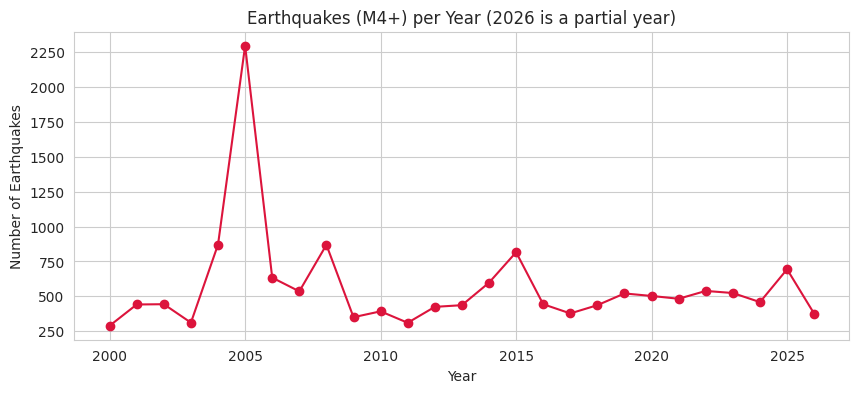

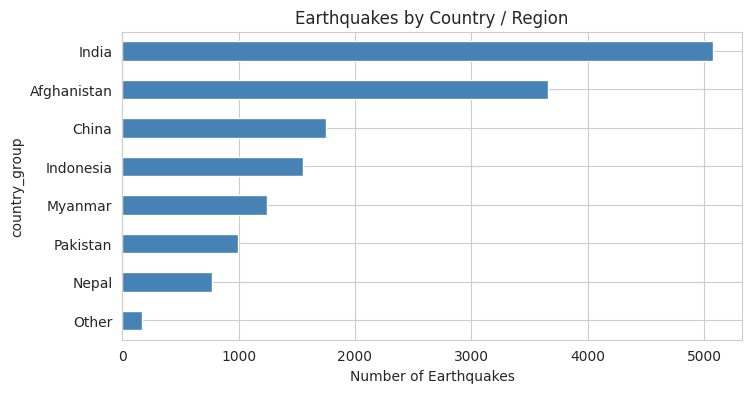

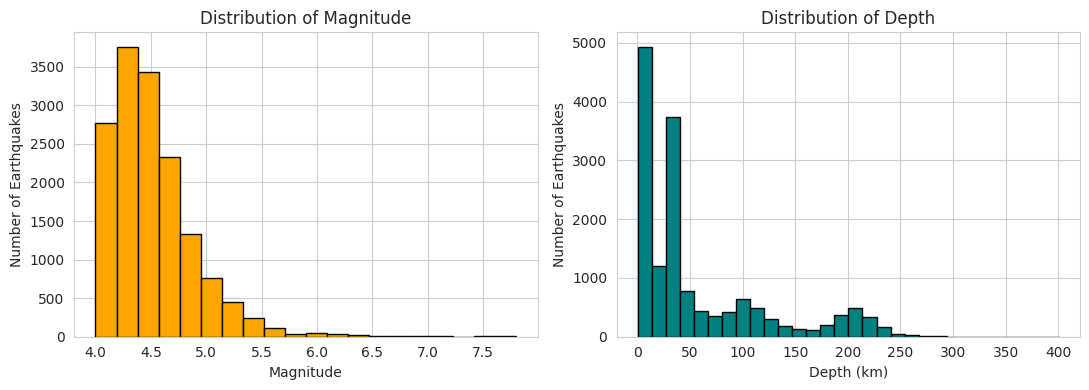

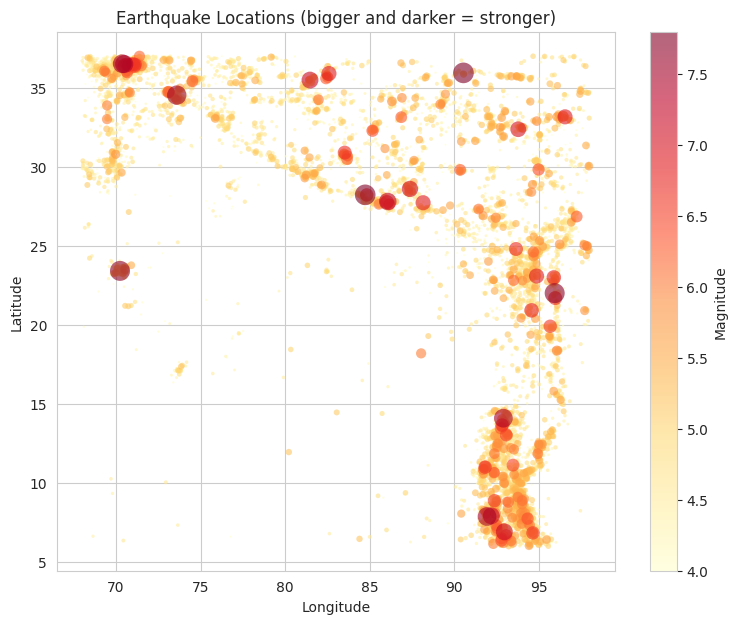

In [7]:
sns.set_style("whitegrid")

# 1. line chart: quakes per year
by_year.plot(kind="line", marker="o", figsize=(10, 4), color="crimson")
plt.title("Earthquakes (M4+) per Year (2026 is a partial year)")
plt.xlabel("Year")
plt.ylabel("Number of Earthquakes")
plt.show()

# 2. bar chart: earthquakes by country
top = df["country_group"].value_counts().head(8)
top.plot(kind="barh", color="steelblue", figsize=(8, 4))
plt.gca().invert_yaxis()
plt.title("Earthquakes by Country / Region")
plt.xlabel("Number of Earthquakes")
plt.show()

# 3. histograms: magnitude and depth
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["mag"], bins=20, color="orange", edgecolor="black")
axes[0].set_title("Distribution of Magnitude")
axes[0].set_xlabel("Magnitude")
axes[0].set_ylabel("Number of Earthquakes")
axes[1].hist(df["depth"], bins=30, color="teal", edgecolor="black")
axes[1].set_title("Distribution of Depth")
axes[1].set_xlabel("Depth (km)")
axes[1].set_ylabel("Number of Earthquakes")
plt.tight_layout()
plt.show()

# 4. map-style scatter plot: where do quakes happen?
d = df.sort_values("mag")
plt.figure(figsize=(9, 7))
sc = plt.scatter(d["longitude"], d["latitude"], c=d["mag"], s=(d["mag"] - 3) ** 3 * 2,
                 cmap="YlOrRd", alpha=0.6, edgecolor="none")
plt.colorbar(sc, label="Magnitude")
plt.title("Earthquake Locations (bigger and darker = stronger)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**Charts 5 to 8**

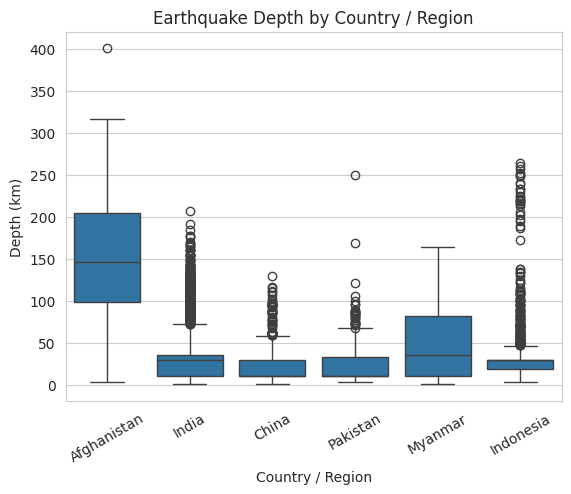

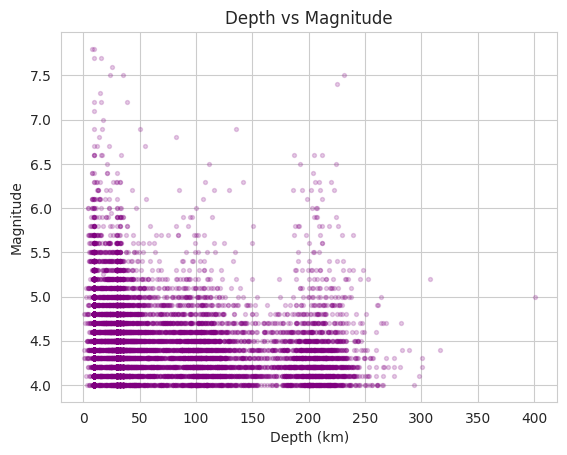

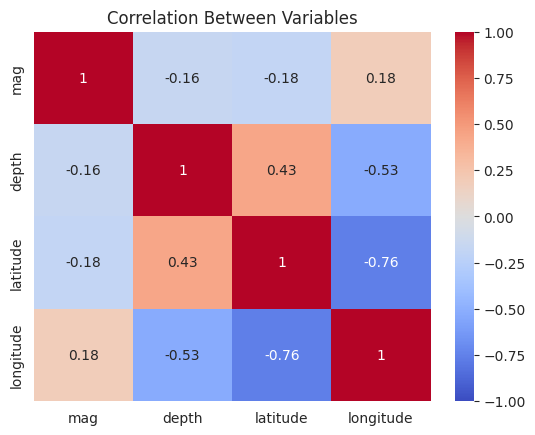

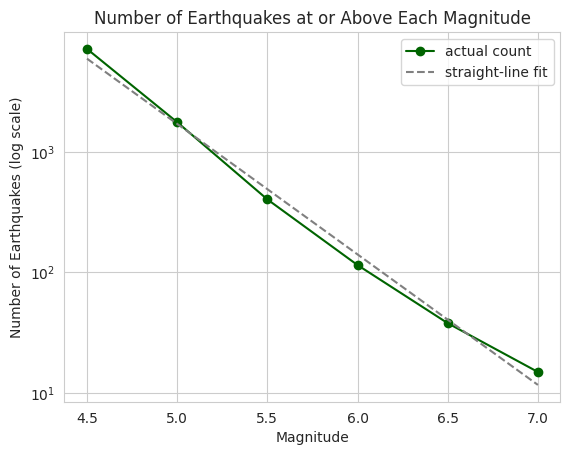

In [8]:
# 5. box plot: depth by country
top6 = df["country_group"].value_counts().head(6).index
sns.boxplot(x="country_group", y="depth", data=df[df["country_group"].isin(top6)])
plt.title("Earthquake Depth by Country / Region")
plt.xlabel("Country / Region")
plt.ylabel("Depth (km)")
plt.xticks(rotation=30)
plt.show()

# 6. scatter plot: depth vs magnitude
plt.scatter(df["depth"], df["mag"], alpha=0.2, s=8, color="purple")
plt.title("Depth vs Magnitude")
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.show()

# 7. heatmap: correlation
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Variables")
plt.show()

# 8. Gutenberg-Richter plot: bigger quakes are much rarer
plt.semilogy(thresholds, counts_mag, marker="o", color="darkgreen", label="actual count")
fit = 10 ** (intercept + slope * np.array(thresholds))
plt.semilogy(thresholds, fit, "--", color="gray", label="straight-line fit")
plt.title("Number of Earthquakes at or Above Each Magnitude")
plt.xlabel("Magnitude")
plt.ylabel("Number of Earthquakes (log scale)")
plt.legend()
plt.show()

In [9]:
from google.colab import files
files.download("india_earthquakes_raw.csv")
files.download("india_earthquakes_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>